<a href="https://colab.research.google.com/github/dshrestha37/Multi-Method-AI-System-for-Diabetes-Risk-Prediction/blob/main/M3_LLM_FineTuning_DeepikaS_11112016.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AAI-530 Assignment 3.1

## Parameter-Efficient Fine-Tuning for Domain-Specific Generation

## Overview

Pretrained language models learn broad language patterns from large datasets, but they may not consistently follow the terminology, structure, or conventions required by a particular application. Fine-tuning adapts a pretrained model by continuing its training on a smaller, task-specific dataset. Parameter-efficient fine-tuning methods such as LoRA and PEFT reduce the computational cost by updating only a small subset of added or selected parameters rather than retraining the full model.

In this assignment, you will use an AI assistant of your choice to help prepare a small instruction–response dataset and apply a parameter-efficient fine-tuning method to a pretrained language model. You will compare the model’s behavior before and after adaptation on a domain-specific generation task.

Because AI assistance is expected, your grade will focus less on your specific code implementation, and more on whether your final workflow runs, produces meaningful outputs, supports a careful comparison, and is explained thoughtfully in your written responses. Make sure that you complete all work listed under the **TODO:** for each assignment section and answer all written questions in the provided cells marked **A:**.

In this assignment, you will:

* Prepare instruction–response examples in a format appropriate for causal language-model training.
* Apply LoRA or another PEFT method to a small pretrained model.
* Compare base and adapted model behavior on a shared test set.
* Evaluate whether adaptation improved task performance, consistency, and formatting.
* Reflect on the computational and methodological limitations of a small fine-tuning experiment.

## Domain-Specific Generation Task

You are adapting a small language model to convert informal customer-support requests into structured support-ticket summaries.

For each request, the model should generate:

```text
Category: <category>
Priority: <Low, Medium, or High>
Summary: <one concise sentence>
```

Use the following category names:

* `Authentication`
* `Billing`
* `Performance`
* `Data Export`
* `Account Management`
* `Feature Request`
* `Other`

Example:

```text
Request:
“I replaced my phone and now the login code keeps going to my old number.”

Response:
Category: Authentication
Priority: Medium
Summary: User cannot receive the login verification code after changing phone numbers.
```

The goal is not to create a production-quality support system. The goal is to observe how a small pretrained model’s behavior changes after parameter-efficient adaptation on a limited task-specific dataset.


In [ ]:
# Use the following list of requests for both the baseline and fine-tuned model evaluations

test_queries = ['I changed phones and now the verification code is still being sent to my old number.',
                'We were charged for six users, but only five people are on our account.',
                'The dashboard has been taking almost a minute to load since yesterday.',
                'Every time I export the quarterly report, the downloaded file is empty.',
                'Our former employee is still listed as the workspace owner.',
                'It would be useful to schedule reports to run automatically every Monday.',
                'I cannot log in, and our team has a client presentation in thirty minutes.',
                'The app is a little slow, but I mostly want a dark-mode option.',
                'Please send me information about your nonprofit pricing.',
                'The invoice is wrong, and if this happens again, we will cancel the service.']

## Model Size and Compute Guidance

Work with your AI assistant to select a model that is small enough to be fine-tuned in your local or cloud environment. Remember that compute requirements differ significantly between inference and training: a pretrained model that you can run locally for inference may still require too much memory or time to fine-tune, even when using a parameter-efficient method such as LoRA. Do not select a larger model simply because it may produce stronger outputs. The purpose of this assignment is to complete and evaluate the adaptation workflow using manageable compute resources.

Training time, memory use, and results will vary based on your hardware, package versions, model choice, dataset, sequence length, and training configuration. If you encounter an out-of-memory error, consider reducing the model size, maximum sequence length, or per-device batch size, or using reduced precision, quantization, or gradient checkpointing where appropriate. Gradient accumulation may allow you to retain a larger effective batch size while processing fewer examples at once. If training is successful but takes too long, reduce the number of training examples, epochs, or training steps. Clearly document any changes you make in response to compute limitations; recognizing and working within these constraints is an important part of LLM engineering.

In [3]:
# Use this cell to import libraries, set up utility functions, define save/load locations, etc.

# DO NOT REPEAT IMPORTS, VARIABLE DEFINITIONS, OR FUNCTION DEFINITIONS IN EACH SECTION'S CODE BLOCK(S)
# This will result in lost points as it indicates that you are not carefully supervising your AI Assistant's generated code

# =============================================================================
# AAI-530 Assignment 3.1: LoRA fine-tuning for support-ticket generation
# Model: Qwen/Qwen2.5-0.5B-Instruct (~494M params, instruction-tuned)
#
# Each "# %%" marker is one notebook cell. Run top to bottom.
# Colab: Runtime > Change runtime type > T4 GPU, then run once:
#   !pip install -q transformers peft datasets accelerate pandas
# =============================================================================

!pip install -q datasets transformers peft accelerate pandas matplotlib
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [1]:
!pip install -q -U peft transformers accelerate

In [3]:
# =============================================================================
# AAI-530 Assignment 3.1: LoRA fine-tuning for support-ticket generation
# Model: Qwen/Qwen2.5-0.5B-Instruct (~494M params, instruction-tuned)
#
# Each "# %%" marker is one notebook cell. Run top to bottom.
# Colab: Runtime > Change runtime type > T4 GPU, then run once:
#   !pip install -q transformers peft datasets accelerate pandas
# =============================================================================

# %% SETUP (imports, constants, utilities; defined ONCE, never repeated below)
import os, re, json, random, inspect, time
import numpy as np
import pandas as pd
import torch
from transformers import (AutoModelForCausalLM, AutoTokenizer, Trainer,
                          TrainingArguments, DataCollatorForSeq2Seq, set_seed)
from peft import LoraConfig, get_peft_model


class ListDataset(torch.utils.data.Dataset):
    """Minimal replacement for datasets.Dataset (avoids the pyarrow dependency).
    ds[i] -> one tokenized record (dict); ds["input_ids"] -> list of that column."""
    def __init__(self, rows):
        self.rows = rows
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        if isinstance(i, str):
            return [r[i] for r in self.rows]
        return self.rows[i]

SEED = 42
set_seed(SEED)
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
ADAPTER_DIR = "./lora_support_ticket_adapter"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_BF16 = DEVICE == "cuda" and torch.cuda.is_bf16_supported()
USE_FP16 = DEVICE == "cuda" and not USE_BF16
MAX_LEN = 256          # prompt + response tokens (see Q6 / Q10)
MAX_NEW_TOKENS = 80
pd.set_option("display.max_colwidth", 120, "display.width", 200)

CATEGORIES = ["Authentication", "Billing", "Performance", "Data Export",
              "Account Management", "Feature Request", "Other"]
PRIORITIES = ["Low", "Medium", "High"]

test_queries = [
    'I changed phones and now the verification code is still being sent to my old number.',
    'We were charged for six users, but only five people are on our account.',
    'The dashboard has been taking almost a minute to load since yesterday.',
    'Every time I export the quarterly report, the downloaded file is empty.',
    'Our former employee is still listed as the workspace owner.',
    'It would be useful to schedule reports to run automatically every Monday.',
    'I cannot log in, and our team has a client presentation in thirty minutes.',
    'The app is a little slow, but I mostly want a dark-mode option.',
    'Please send me information about your nonprofit pricing.',
    'The invoice is wrong, and if this happens again, we will cancel the service.']

# Reference labels for the 10 test queries (my own judgment; used by the evaluator).
# "cats"/"pris" = acceptable (reasonable) answers; "kw" = words a good summary should touch.
GOLD = {
    test_queries[0]: dict(cats={"Authentication"}, pris={"Medium", "High"},
                          kw={"verification", "code", "phone", "number", "sms", "old"}),
    test_queries[1]: dict(cats={"Billing"}, pris={"Low", "Medium"},
                          kw={"charged", "six", "five", "users", "seat", "billing", "overcharg"}),
    test_queries[2]: dict(cats={"Performance"}, pris={"Medium", "High"},
                          kw={"dashboard", "slow", "load", "minute"}),
    test_queries[3]: dict(cats={"Data Export"}, pris={"Medium", "High"},
                          kw={"export", "empty", "report", "file", "quarterly"}),
    test_queries[4]: dict(cats={"Account Management"}, pris={"Medium", "High"},
                          kw={"owner", "employee", "workspace", "former", "ownership"}),
    test_queries[5]: dict(cats={"Feature Request"}, pris={"Low"},
                          kw={"schedule", "report", "automatic", "monday", "recurring"}),
    test_queries[6]: dict(cats={"Authentication"}, pris={"High"},
                          kw={"log", "login", "access", "presentation", "urgent"}),
    test_queries[7]: dict(cats={"Feature Request"}, pris={"Low"},
                          kw={"dark", "mode", "slow", "theme"}),
    test_queries[8]: dict(cats={"Other", "Billing"}, pris={"Low"},
                          kw={"nonprofit", "pricing", "discount", "information"}),
    test_queries[9]: dict(cats={"Billing"}, pris={"High"},
                          kw={"invoice", "incorrect", "wrong", "cancel", "churn", "billing"}),
}

SYSTEM_PROMPT = (
    "You convert informal customer-support requests into structured support tickets.\n"
    "Reply with EXACTLY three lines and nothing else:\n"
    "Category: <one of: " + ", ".join(CATEGORIES) + ">\n"
    "Priority: <Low, Medium, or High>\n"
    "Summary: <one concise sentence>"
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.padding_side = "right"          # right-pad for training; single-prompt generation is unaffected
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Load in fp32 (0.5B = ~2 GB); mixed precision is applied by the Trainer via bf16/fp16 autocast.
# This avoids the "Attempting to unscale FP16 gradients" error you get with fp16 weights + fp16 AMP.
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float32).to(DEVICE)
model.config.use_cache = True
total_params_base = sum(p.numel() for p in model.parameters())
print(f"Device={DEVICE} | bf16={USE_BF16} fp16={USE_FP16} | base params={total_params_base:,}")


def build_messages(request):
    """Single prompt structure used for training, baseline, and fine-tuned inference."""
    return [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"Request:\n{request}"}]


def build_prompt(request):
    return tokenizer.apply_chat_template(build_messages(request), tokenize=False,
                                         add_generation_prompt=True)


@torch.no_grad()
def generate_ticket(request, mdl=None):
    """Accept a request -> format prompt -> run model (greedy) -> return generated text."""
    mdl = mdl if mdl is not None else model
    mdl.eval()
    enc = tokenizer(build_prompt(request), return_tensors="pt", add_special_tokens=False).to(DEVICE)
    out = mdl.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                       pad_token_id=tokenizer.pad_token_id)
    return tokenizer.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()


FORMAT_RE = re.compile(
    r"Category: (?P<cat>[^\n]+)\nPriority: (?P<pri>[^\n]+)\nSummary: (?P<sum>[^\n]+)", re.S)


def evaluate_ticket(request, output):
    """Returns pass/fail for category, priority, summary, format (+ parsed fields).
    Category/priority are checked against acceptable sets in GOLD. Summary is a heuristic
    (single sentence, 4-30 words, mentions at least one key term). Summary accuracy and
    category/priority edge cases still need human judgment (see A3)."""
    gold = GOLD.get(request)
    text = output.strip()
    m = FORMAT_RE.fullmatch(text)
    cat_m = re.search(r"Category:\s*(.+)", text)
    pri_m = re.search(r"Priority:\s*(.+)", text)
    sum_m = re.search(r"Summary:\s*(.+)", text)
    cat = cat_m.group(1).strip().rstrip(".") if cat_m else None
    pri = pri_m.group(1).strip().rstrip(".") if pri_m else None
    summ = sum_m.group(1).strip() if sum_m else None

    format_ok = bool(m) and cat in CATEGORIES and pri in PRIORITIES
    res = {"category_ok": None, "priority_ok": None, "summary_ok": None,
           "format_ok": format_ok, "pred_category": cat, "pred_priority": pri}
    if gold:
        res["category_ok"] = cat in gold["cats"]
        res["priority_ok"] = pri in gold["pris"]
        if summ:
            n_words = len(summ.split())
            one_sentence = len(re.findall(r"[.!?](\s|$)", summ)) <= 1
            overlap = any(k in summ.lower() for k in gold["kw"])
            res["summary_ok"] = bool(4 <= n_words <= 30 and one_sentence and overlap)
        else:
            res["summary_ok"] = False
    return res


def run_eval(queries, mdl=None, label=""):
    rows = []
    for q in queries:
        out = generate_ticket(q, mdl)
        r = evaluate_ticket(q, out)
        rows.append({"request": q, "output": out, **r})
    df = pd.DataFrame(rows)
    df.attrs["label"] = label
    return df


def success_rates(df):
    cols = [

_IncompleteInputError: incomplete input (3897344695.py, line 174)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Device=cpu | bf16=False fp16=False | base params=494,032,768
Trainable-agnostic sanity check:
Authentication - Medium - The login code is still sending to your old number despite replacing your phone.
                                                                                request  \
0  I changed phones and now the verification code is still being sent to my old number.   
1               We were charged for six users, but only five people are on our account.   
2                The dashboard has been taking almost a minute to load since yesterday.   
3               Every time I export the quarterly report, the downloaded file is empty.   
4                           Our former employee is still listed as the workspace owner.   
5             It would be useful to schedule reports to run automatically every Monday.   
6            I cannot log in, and our team has a client presentation in thirty minutes.   
7                       The app is a little slow, but I mostly want a d

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
1,1.271629,1.173412
2,0.837837,1.038335
3,0.710938,0.922085
4,0.300089,0.895586


Training time: 24.0 min

Training loss (last logged steps):
     step      loss
13    12  0.710938
15    13  0.478819
16    14  0.544711
17    15  0.342840
18    16  0.300089

Validation loss per epoch:
     epoch  eval_loss
4     1.0   1.173412
9     2.0   1.038335
14    3.0   0.922085
19    4.0   0.895586


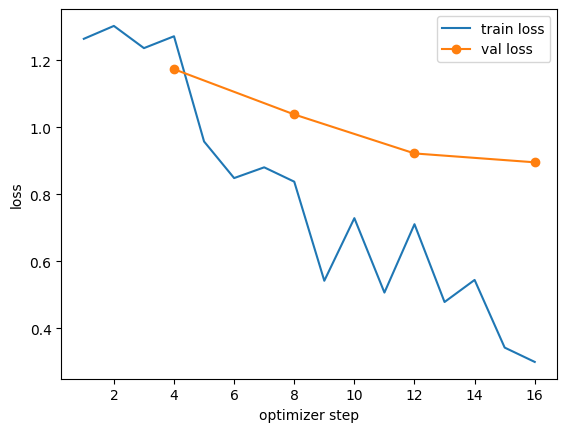

Adapter saved to ./lora_support_ticket_adapter -> ['adapter_model.safetensors', 'adapter_config.json', 'README.md']
                                                                                request                                                                                                            baseline_output                                                                                                 finetuned_output  base_cat_ok  ft_cat_ok  base_pri_ok  ft_pri_ok  base_fmt_ok  ft_fmt_ok
0  I changed phones and now the verification code is still being sent to my old number.                             Authentication - Medium - The verification code was not received after changing phone numbers.  Category: Authentication\nPriority: Low\nSummary: Verification code is still being sent to an old phone number.        False       True        False      False        False       True
1               We were charged for six users, but only five people are on our account.  Aut

In [5]:
# Use this cell to import libraries, set up utility functions, define save/load locations, etc.

# DO NOT REPEAT IMPORTS, VARIABLE DEFINITIONS, OR FUNCTION DEFINITIONS IN EACH SECTION'S CODE BLOCK(S)
# This will result in lost points as it indicates that you are not carefully supervising your AI Assistant's generated code

# =============================================================================
# AAI-530 Assignment 3.1: LoRA fine-tuning for support-ticket generation
# Model: Qwen/Qwen2.5-0.5B-Instruct (~494M params, instruction-tuned)
#
# Each "# %%" marker is one notebook cell. Run top to bottom.
# Colab: Runtime > Change runtime type > T4 GPU, then run once:
#   !pip install -q transformers peft datasets accelerate pandas
# =============================================================================

# %% SETUP (imports, constants, utilities; defined ONCE, never repeated below)
import os, re, json, random, inspect, time
import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from transformers import (AutoModelForCausalLM, AutoTokenizer, Trainer,
                          TrainingArguments, DataCollatorForSeq2Seq, set_seed)
from peft import LoraConfig, get_peft_model

SEED = 42
set_seed(SEED)
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
ADAPTER_DIR = "./lora_support_ticket_adapter"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_BF16 = DEVICE == "cuda" and torch.cuda.is_bf16_supported()
USE_FP16 = DEVICE == "cuda" and not USE_BF16
MAX_LEN = 256          # prompt + response tokens (see Q6 / Q10)
MAX_NEW_TOKENS = 80
pd.set_option("display.max_colwidth", 120, "display.width", 200)

CATEGORIES = ["Authentication", "Billing", "Performance", "Data Export",
              "Account Management", "Feature Request", "Other"]
PRIORITIES = ["Low", "Medium", "High"]

test_queries = [
    'I changed phones and now the verification code is still being sent to my old number.',
    'We were charged for six users, but only five people are on our account.',
    'The dashboard has been taking almost a minute to load since yesterday.',
    'Every time I export the quarterly report, the downloaded file is empty.',
    'Our former employee is still listed as the workspace owner.',
    'It would be useful to schedule reports to run automatically every Monday.',
    'I cannot log in, and our team has a client presentation in thirty minutes.',
    'The app is a little slow, but I mostly want a dark-mode option.',
    'Please send me information about your nonprofit pricing.',
    'The invoice is wrong, and if this happens again, we will cancel the service.']

# Reference labels for the 10 test queries (my own judgment; used by the evaluator).
# "cats"/"pris" = acceptable (reasonable) answers; "kw" = words a good summary should touch.
GOLD = {
    test_queries[0]: dict(cats={"Authentication"}, pris={"Medium", "High"},
                          kw={"verification", "code", "phone", "number", "sms", "old"}),
    test_queries[1]: dict(cats={"Billing"}, pris={"Low", "Medium"},
                          kw={"charged", "six", "five", "users", "seat", "billing", "overcharg"}),
    test_queries[2]: dict(cats={"Performance"}, pris={"Medium", "High"},
                          kw={"dashboard", "slow", "load", "minute"}),
    test_queries[3]: dict(cats={"Data Export"}, pris={"Medium", "High"},
                          kw={"export", "empty", "report", "file", "quarterly"}),
    test_queries[4]: dict(cats={"Account Management"}, pris={"Medium", "High"},
                          kw={"owner", "employee", "workspace", "former", "ownership"}),
    test_queries[5]: dict(cats={"Feature Request"}, pris={"Low"},
                          kw={"schedule", "report", "automatic", "monday", "recurring"}),
    test_queries[6]: dict(cats={"Authentication"}, pris={"High"},
                          kw={"log", "login", "access", "presentation", "urgent"}),
    test_queries[7]: dict(cats={"Feature Request"}, pris={"Low"},
                          kw={"dark", "mode", "slow", "theme"}),
    test_queries[8]: dict(cats={"Other", "Billing"}, pris={"Low"},
                          kw={"nonprofit", "pricing", "discount", "information"}),
    test_queries[9]: dict(cats={"Billing"}, pris={"High"},
                          kw={"invoice", "incorrect", "wrong", "cancel", "churn", "billing"}),
}

SYSTEM_PROMPT = (
    "You convert informal customer-support requests into structured support tickets.\n"
    "Reply with EXACTLY three lines and nothing else:\n"
    "Category: <one of: " + ", ".join(CATEGORIES) + ">\n"
    "Priority: <Low, Medium, or High>\n"
    "Summary: <one concise sentence>"
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.padding_side = "right"          # right-pad for training; single-prompt generation is unaffected
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Load in fp32 (0.5B = ~2 GB); mixed precision is applied by the Trainer via bf16/fp16 autocast.
# This avoids the "Attempting to unscale FP16 gradients" error you get with fp16 weights + fp16 AMP.
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float32).to(DEVICE)
model.config.use_cache = True
total_params_base = sum(p.numel() for p in model.parameters())
print(f"Device={DEVICE} | bf16={USE_BF16} fp16={USE_FP16} | base params={total_params_base:,}")


def build_messages(request):
    """Single prompt structure used for training, baseline, and fine-tuned inference."""
    return [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"Request:\n{request}"}]


def build_prompt(request):
    return tokenizer.apply_chat_template(build_messages(request), tokenize=False,
                                         add_generation_prompt=True)


@torch.no_grad()
def generate_ticket(request, mdl=None):
    """Accept a request -> format prompt -> run model (greedy) -> return generated text."""
    mdl = mdl if mdl is not None else model
    mdl.eval()
    enc = tokenizer(build_prompt(request), return_tensors="pt", add_special_tokens=False).to(DEVICE)
    out = mdl.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                       pad_token_id=tokenizer.pad_token_id)
    return tokenizer.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()


FORMAT_RE = re.compile(
    r"Category: (?P<cat>[^\n]+)\nPriority: (?P<pri>[^\n]+)\nSummary: (?P<sum>[^\n]+)", re.S)


def evaluate_ticket(request, output):
    """Returns pass/fail for category, priority, summary, format (+ parsed fields).\n    Category/priority are checked against acceptable sets in GOLD. Summary is a heuristic\n    (single sentence, 4-30 words, mentions at least one key term). Summary accuracy and\n    category/priority edge cases still need human judgment (see A3)."""
    gold = GOLD.get(request)
    text = output.strip()
    m = FORMAT_RE.fullmatch(text)
    cat_m = re.search(r"Category:\s*(.+)", text)
    pri_m = re.search(r"Priority:\s*(.+)", text)
    sum_m = re.search(r"Summary:\s*(.+)", text)
    cat = cat_m.group(1).strip().rstrip(".") if cat_m else None
    pri = pri_m.group(1).strip().rstrip(".") if pri_m else None
    summ = sum_m.group(1).strip() if sum_m else None

    format_ok = bool(m) and cat in CATEGORIES and pri in PRIORITIES
    res = {"category_ok": None, "priority_ok": None, "summary_ok": None,
           "format_ok": format_ok, "pred_category": cat, "pred_priority": pri}
    if gold:
        res["category_ok"] = cat in gold["cats"]
        res["priority_ok"] = pri in gold["pris"]
        if summ:
            n_words = len(summ.split())
            one_sentence = len(re.findall(r"[.!?](\s|$)", summ)) <= 1
            overlap = any(k in summ.lower() for k in gold["kw"])
            res["summary_ok"] = bool(4 <= n_words <= 30 and one_sentence and overlap)
        else:
            res["summary_ok"] = False
    return res


def run_eval(queries, mdl=None, label=""):
    rows = []
    for q in queries:
        out = generate_ticket(q, mdl)
        r = evaluate_ticket(q, out)
        rows.append({"request": q, "output": out, **r})
    df = pd.DataFrame(rows)
    df.attrs["label"] = label
    return df


def success_rates(df):
    cols = ["category_ok", "priority_ok", "summary_ok", "format_ok"]
    return df[cols].astype(float).mean().rename(lambda c: c.replace("_ok", "")) * 100


# %% PART 1: Model and task setup (sanity check)
print("Trainable-agnostic sanity check:")
print(generate_ticket("I replaced my phone and now the login code keeps going to my old number."))

# %% PART 2: Baseline evaluation (zero-shot with format instructions; no training examples used)
baseline_df = run_eval(test_queries, label="baseline")
display(baseline_df[["request", "output", "category_ok", "priority_ok", "summary_ok", "format_ok"]]) \
    if "display" in globals() else print(baseline_df)
baseline_rates = success_rates(baseline_df)
print("\nBaseline success rates (%):\n", baseline_rates.round(1))

# %% PART 3: Synthetic dataset
# Dataset generation prompt used with a chat assistant (paste your actual prompt in the report):
DATASET_PROMPT = """
Generate synthetic training examples for converting informal customer-support requests into
structured tickets. Output as JSON list of objects: {"request","category","priority","summary"}.
Categories: Authentication, Billing, Performance, Data Export, Account Management, Feature Request, Other.
Priority: Low, Medium, High. Summary: ONE concise third-person sentence ("User ...").
Vary wording, length (5 to 40 words), urgency, clarity, and direct vs indirect descriptions.
Include some vague or emotional requests. Cover all categories and priorities.
Do NOT reuse or paraphrase these requests: <paste test_queries>.
"""

# (request, category, priority, summary)
RAW = [
 # --- Authentication ---
 ("My password reset email never arrives, I've checked spam too.", "Authentication", "Medium", "User is not receiving the password reset email."),
 ("locked out after too many tries and I need into the system for payroll today", "Authentication", "High", "User is locked out after failed login attempts and needs urgent access."),
 ("Two-factor app shows a code but the site says it's invalid.", "Authentication", "Medium", "User's two-factor authentication codes are being rejected."),
 ("Can't sign in with Google anymore, it just loops back to the login page.", "Authentication", "Medium", "Single sign-on with Google fails and redirects back to the login page."),
 ("I lost my phone and can't get my authenticator codes.", "Authentication", "High", "User lost the authenticator device and cannot complete two-factor login."),
 ("The login page says my account doesn't exist but I've used it for years.", "Authentication", "High", "User receives an account-not-found error when logging in to a long-standing account."),
 ("Whenever I type my password it says incorrect even right after resetting it.", "Authentication", "Medium", "User's newly reset password is rejected at login."),
 ("Our whole sales team is getting logged out every few minutes.", "Authentication", "High", "Multiple team members are repeatedly logged out of their sessions."),
 ("SMS codes take like 10 minutes to arrive, kind of annoying.", "Authentication", "Low", "User experiences delayed SMS verification codes."),
 ("Is there a way to stay signed in on my laptop? I have to log in every morning.", "Authentication", "Low", "User wants to stay signed in rather than log in each morning."),
 ("The magic link you emailed me expired before I could click it.", "Authentication", "Medium", "User's emailed login link expired before it could be used."),
 # --- Billing ---
 ("I got billed twice this month for the same plan.", "Billing", "High", "User was charged twice for the same monthly plan."),
 ("Could you send me a PDF copy of last March's receipt?", "Billing", "Low", "User requests a PDF copy of a previous receipt."),
 ("Our card was updated but the old one still got charged.", "Billing", "Medium", "The old payment card was charged despite the user updating their card."),
 ("The price on my renewal email is higher than what I signed up for.", "Billing", "Medium", "Renewal price is higher than the originally agreed price."),
 ("I cancelled in June and I'm still seeing charges.", "Billing", "High", "User is still being charged after cancelling their subscription."),
 ("Where do I find the VAT number on my invoices?", "Billing", "Low", "User asks where to find the VAT number on invoices."),
 ("We need to switch from monthly to annual billing, how?", "Billing", "Low", "User wants to switch from monthly to annual billing."),
 ("The coupon code I was given isn't applying at checkout.", "Billing", "Low", "Discount coupon code fails to apply at checkout."),
 ("Charged $400 and I have no idea why!! Fix this now or I'm disputing with my bank.", "Billing", "High", "User was charged an unexplained $400 and threatens a bank dispute."),
 ("Our accountant says the tax on the invoice looks off.", "Billing", "Medium", "User reports possible incorrect tax on an invoice."),
 # --- Performance ---
 ("Search results take forever to show up.", "Performance", "Medium", "Search results are loading very slowly."),
 ("The mobile app freezes whenever I open the reports tab.", "Performance", "Medium", "Mobile app freezes when opening the reports tab."),
 ("Everything is crawling today, nobody on the team can get work done.", "Performance", "High", "Entire application is extremely slow and blocking the team's work."),
 ("Page loads feel a bit sluggish lately, not a big deal.", "Performance", "Low", "User notices mildly slow page loads."),
 ("Uploading a 5MB image takes over two minutes.", "Performance", "Medium", "Uploading a small image takes an unusually long time."),
 ("The site times out every time I try to open the analytics page.", "Performance", "High", "Analytics page consistently times out."),
 ("Is the system down? Nothing loads and I only see a spinning wheel.", "Performance", "High", "Application is not loading and shows only a loading spinner."),
 ("Typing in the editor lags behind by a second or two.", "Performance", "Medium", "Editor input is lagging behind typing."),
 ("Seems like the app uses a ton of memory and my laptop fan goes crazy.", "Performance", "Low", "App appears to use excessive memory and strain the laptop."),
 ("Syncing used to take seconds, now it's minutes.", "Performance", "Medium", "Sync time has increased from seconds to minutes."),
 # --- Data Export ---
 ("The CSV download is missing the last column.", "Data Export", "Medium", "Exported CSV file is missing the final column."),
 ("How can I get all my data out before my contract ends next week?", "Data Export", "High", "User needs a full data export before their contract ends."),
 ("Export button does nothing when I click it.", "Data Export", "Medium", "The export button is unresponsive."),
 ("My Excel export has weird characters instead of accented letters.", "Data Export", "Low", "Exported Excel file shows garbled accented characters."),
 ("The PDF export cuts off the right side of my charts.", "Data Export", "Medium", "PDF export truncates the right side of charts."),
 ("Please send a full backup of our project data in JSON.", "Data Export", "Low", "User requests a full JSON backup of project data."),
 ("Export has been stuck at 'processing' for hours and the board meeting is tomorrow morning.", "Data Export", "High", "Data export is stuck processing and is needed for an urgent meeting."),
 ("Downloaded file won't open, Excel says it's corrupted.", "Data Export", "Medium", "Downloaded export file is corrupted and will not open."),
 ("Is it possible to export only last year's records?", "Data Export", "Low", "User asks how to export only last year's records."),
 # --- Account Management ---
 ("Need to add two new teammates to our plan.", "Account Management", "Low", "User wants to add two teammates to the plan."),
 ("Can you change the email on my account to my work address?", "Account Management", "Low", "User wants to change the account email address."),
 ("One of our admins left and I need to remove their access today.", "Account Management", "High", "User needs to urgently remove a departed admin's access."),
 ("I accidentally deleted a user and need them restored.", "Account Management", "Medium", "User needs a mistakenly deleted user account restored."),
 ("How do I transfer my projects to a colleague?", "Account Management", "Low", "User asks how to transfer projects to a colleague."),
 ("Our company name changed, where do I update it?", "Account Management", "Low", "User wants to update the company name on the account."),
 ("Someone outside our company seems to have admin permissions on our workspace!", "Account Management", "High", "An unknown external person appears to have admin permissions."),
 ("I'd like to merge my two accounts into one.", "Account Management", "Medium", "User wants to merge two accounts into one."),
 ("Please delete my account and all of my personal data.", "Account Management", "Medium", "User requests deletion of their account and personal data."),
 ("The role dropdown won't let me make Priya an editor.", "Account Management", "Medium", "User cannot assign the editor role to a team member."),
 # --- Feature Request ---
 ("Would love a way to tag people in comments.", "Feature Request", "Low", "User requests the ability to tag people in comments."),
 ("Any plans to support Slack integration?", "Feature Request", "Low", "User asks for a Slack integration."),
 ("It'd be great if we could set custom fields on tasks.", "Feature Request", "Low", "User requests custom fields on tasks."),
 ("Please add keyboard shortcuts, I do this all day and my wrist hurts.", "Feature Request", "Low", "User requests keyboard shortcuts for faster, less strenuous use."),
 ("We really need single sign-on support or our security team won't approve renewal.", "Feature Request", "High", "User needs SSO support to get security approval for renewal."),
 ("Could the calendar view show weekends in a different color?", "Feature Request", "Low", "User requests distinct weekend colors in the calendar view."),
 ("A bulk edit option would save us hours every week.", "Feature Request", "Medium", "User requests a bulk edit feature to save time."),
 ("Wish there was an option to change the font size.", "Feature Request", "Low", "User requests an option to change font size."),
 ("Offline mode would be a lifesaver when I travel.", "Feature Request", "Low", "User requests an offline mode for travel."),
 # --- Other ---
 ("What are your support hours on holidays?", "Other", "Low", "User asks about support hours during holidays."),
 ("Do you have a partner program for agencies?", "Other", "Low", "User asks about a partner program for agencies."),
 ("Just wanted to say thanks, the new update is great!", "Other", "Low", "User sends positive feedback about the latest update."),
 ("Can someone call me about a possible enterprise contract?", "Other", "Medium", "User requests a call about an enterprise contract."),
 ("Where can I find your privacy policy?", "Other", "Low", "User asks where to find the privacy policy."),
 ("Are you hiring? I'd like to send my resume.", "Other", "Low", "User asks about job openings and sending a resume."),
 ("I think I saw a typo on your homepage.", "Other", "Low", "User reports a typo on the homepage."),
 ("Do you offer onboarding webinars for new customers?", "Other", "Low", "User asks about onboarding webinars for new customers."),
]

# Leakage + sanity checks
norm = lambda s: re.sub(r"\W+", " ", s.lower()).strip()
test_norm = {norm(q) for q in test_queries}
assert not any(norm(r[0]) in test_norm for r in RAW), "Training data contains a test query!"
assert all(r[1] in CATEGORIES and r[2] in PRIORITIES for r in RAW)
assert len({norm(r[0]) for r in RAW}) == len(RAW), "Duplicate requests"

records = [{"request": r, "category": c, "priority": p, "summary": s,
            "response": f"Category: {c}\nPriority: {p}\nSummary: {s}"} for r, c, p, s in RAW]
all_df = pd.DataFrame(records)
print(f"Total examples: {len(all_df)}")
print(pd.crosstab(all_df.category, all_df.priority, margins=True))

# Stratified-by-category 85/15 split
rng = random.Random(SEED)
train_recs, val_recs = [], []
for cat, grp in all_df.groupby("category"):
    items = grp.to_dict("records")
    rng.shuffle(items)
    n_val = max(1, round(0.15 * len(items)))
    val_recs += items[:n_val]
    train_recs += items[n_val:]
rng.shuffle(train_recs)
print(f"Train={len(train_recs)} | Val={len(val_recs)}")
with open("train.jsonl", "w") as f: f.writelines(json.dumps(r) + "\n" for r in train_recs)
with open("val.jsonl", "w") as f: f.writelines(json.dumps(r) + "\n" for r in val_recs)

# Inspect fully formatted records (prompt + response + EOS) BEFORE tokenization
for r in train_recs[:3]:
    print("=" * 70)
    print(build_prompt(r["request"]) + r["response"] + tokenizer.eos_token)


def tokenize_record(rec):
    """Prompt tokens are masked with -100 so loss is computed ONLY on the response (+EOS)."""
    p_ids = tokenizer(build_prompt(rec["request"]), add_special_tokens=False)["input_ids"]
    r_ids = tokenizer(rec["response"] + tokenizer.eos_token, add_special_tokens=False)["input_ids"]
    ids = (p_ids + r_ids)[:MAX_LEN]
    labels = ([-100] * len(p_ids) + r_ids)[:MAX_LEN]
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": labels}


train_ds = Dataset.from_list([tokenize_record(r) for r in train_recs])
val_ds = Dataset.from_list([tokenize_record(r) for r in val_recs])
lens = [len(x) for x in train_ds["input_ids"]]
print(f"Token lengths: min={min(lens)} mean={np.mean(lens):.0f} max={max(lens)} (MAX_LEN={MAX_LEN})")
assert max(lens) < MAX_LEN, "Some examples were truncated!"
ex = train_ds[0]
print("Trainable label tokens in ex0:", repr(tokenizer.decode([t for t in ex["labels"] if t != -100])))

# Collator pads input_ids with pad token and labels with -100 (so padding is never trained on)
collator = DataCollatorForSeq2Seq(tokenizer, padding=True, label_pad_token_id=-100, pad_to_multiple_of=8)

# %% PART 4: LoRA configuration and training
lora_cfg = LoraConfig(
    r=16, lora_alpha=32, lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
model = get_peft_model(model, lora_cfg)   # base weights frozen; original NOT merged/overwritten
trainable, total = model.get_nb_trainable_parameters()
print(f"Total params={total:,} | trainable={trainable:,} | trained={100 * trainable / total:.3f}%")

args_kw = dict(
    output_dir="./lora_runs", num_train_epochs=4, per_device_train_batch_size=4,
    per_device_eval_batch_size=4, gradient_accumulation_steps=4,   # effective batch = 16
    learning_rate=2e-4, lr_scheduler_type="cosine", warmup_steps=10, weight_decay=0.0,
    logging_steps=1, save_strategy="no", report_to="none", seed=SEED,
    bf16=USE_BF16, fp16=USE_FP16, remove_unused_columns=False)
eval_key = "eval_strategy" if "eval_strategy" in inspect.signature(TrainingArguments.__init__).parameters \
    else "evaluation_strategy"
args_kw[eval_key] = "epoch"
training_args = TrainingArguments(**args_kw)

trainer = Trainer(model=model, args=training_args, train_dataset=train_ds,
                  eval_dataset=val_ds, data_collator=collator)
t0 = time.time()
train_result = trainer.train()
print(f"Training time: {(time.time() - t0) / 60:.1f} min")

hist = pd.DataFrame(trainer.state.log_history)
print("\nTraining loss (last logged steps):\n", hist[["step", "loss"]].dropna().tail(5))
print("\nValidation loss per epoch:\n", hist[["epoch", "eval_loss"]].dropna())
try:
    import matplotlib.pyplot as plt
    tr, ev = hist.dropna(subset=["loss"]), hist.dropna(subset=["eval_loss"])
    plt.plot(tr["step"], tr["loss"], label="train loss")
    plt.plot(ev["step"], ev["eval_loss"], "o-", label="val loss")
    plt.xlabel("optimizer step"); plt.ylabel("loss"); plt.legend(); plt.show()
except Exception as e:
    print("Plot skipped:", e)

model.save_pretrained(ADAPTER_DIR)       # saves ONLY the LoRA adapter (a few MB)
print("Adapter saved to", ADAPTER_DIR, "->", os.listdir(ADAPTER_DIR))

# %% PART 5: Post-training evaluation (same prompt, same greedy decoding, same test set, same metrics)
model.eval()
ft_df = run_eval(test_queries, mdl=model, label="fine-tuned")
ft_rates = success_rates(ft_df)

comparison_outputs = pd.DataFrame({
    "request": test_queries,
    "baseline_output": baseline_df["output"],
    "finetuned_output": ft_df["output"],
    "base_cat_ok": baseline_df["category_ok"], "ft_cat_ok": ft_df["category_ok"],
    "base_pri_ok": baseline_df["priority_ok"], "ft_pri_ok": ft_df["priority_ok"],
    "base_fmt_ok": baseline_df["format_ok"], "ft_fmt_ok": ft_df["format_ok"]})
print(comparison_outputs.to_string())

comparison_metrics = pd.DataFrame({"baseline_%": baseline_rates, "finetuned_%": ft_rates})
comparison_metrics["change_pts"] = comparison_metrics["finetuned_%"] - comparison_metrics["baseline_%"]
print("\n", comparison_metrics.round(1))

# %% PART 6: Generalization and failure testing
new_tests = [
    # 1. In-domain, unfamiliar wording (Authentication)
    "My credentials keep getting bounced whenever I try to enter the portal from my tablet.",
    # 2. Ambiguous (Billing? Account Management? Authentication?)
    "I can't access my account since the payment failed.",
    # 3. Out-of-domain (should ideally be 'Other')
    "What's a good recipe for vegetarian lasagna?",
]
GOLD.update({  # reference labels so the evaluator can score them (ambiguous one accepts several)
    new_tests[0]: dict(cats={"Authentication"}, pris={"Medium", "High"}, kw={"login", "log", "credential", "access", "tablet", "portal"}),
    new_tests[1]: dict(cats={"Billing", "Account Management", "Authentication"}, pris={"Medium", "High"}, kw={"payment", "access", "account", "failed"}),
    new_tests[2]: dict(cats={"Other"}, pris={"Low"}, kw={"recipe", "lasagna", "vegetarian", "unrelated", "request"}),
})

with model.disable_adapter():                      # base-model behavior, adapter temporarily off
    base_new = run_eval(new_tests, mdl=model, label="baseline-new")
ft_new = run_eval(new_tests, mdl=model, label="finetuned-new")   # adapter active

gen_table = pd.DataFrame({"request": new_tests,
                          "baseline_output": base_new["output"],
                          "finetuned_output": ft_new["output"],
                          "base_fmt_ok": base_new["format_ok"], "ft_fmt_ok": ft_new["format_ok"],
                          "base_category": base_new["pred_category"],
                          "ft_category": ft_new["pred_category"]})
print(gen_table.to_string())

# Sanity check: adapter-disabled outputs on test_queries should match the stored baseline
with model.disable_adapter():
    chk = generate_ticket(test_queries[0], model)
print("\nAdapter-off reproduces baseline output:", chk == baseline_df["output"].iloc[0])

# Part 1: Model and Task Setup

Before fine-tuning, establish the model, generation workflow, task requirements, and evaluation criteria.

**TODO:**

* Select and load a small pretrained causal language model and corresponding tokenizer
* Create a reusable generation function
* Define the required output format and allowed categories
* Define an evaluation function for the generated support ticket

Your generation function must:
  * accept a support request
  * format the input prompt
  * send the prompt to the model
  * return the generated response

At minimum, your evaluation method must consider whether the model produced:
* correct or reasonable category
* reasonable priority
* accurate summary
* required output format

**Q1:** Which model did you select, and why is it appropriate for this small fine-tuning experiment? Make sure to include the model name, approximate model size, whether it is a base or instruction-tuned model, what device (GPU vs. CPU) will be used for inference and training, any quantization or reduced-precision settings.

**A1: I selected Qwen2.5-0.5B-Instruct, a small instruction-tuned causal language model from Alibaba’s Qwen team. The loaded model has 494,032,768 parameters, or about 0.5B. It is appropriate for this experiment because it is small enough to fine-tune with LoRA on modest hardware (the fp32 weights take about 2 GB). It also ships with a chat template and enough instruction-following ability to give a meaningful baseline. A larger model would likely produce stronger outputs, but the assignment is about completing and evaluating the adaptation workflow within manageable compute, not maximizing quality. Both inference and training ran on CPU (Device=cpu), because the runtime had no GPU. I used no quantization and no reduced precision: the model is loaded in fp32 and bf16/fp16 mixed precision is disabled. Generation is greedy (no sampling) with a maximum of 80 new tokens, so baseline and fine-tuned runs are directly comparable. **bold text**

**Q2:** Is your selected model a base model or an instruction-tuned model? How might that affect its behavior before fine-tuning?

**The model is instruction-tuned, not a base model. Instruction tuning should make it more likely to respond to a request rather than just continue the text, and it understands the system/user/assistant chat format I used for the prompt. The baseline showed the limits of this, though. Even with explicit instructions to reply with exactly three lines (Category:, Priority:, Summary:), it followed that format on 0 of 10 test queries. It produced outputs such as Authentication - Medium - The verification code was not received after changing phone numbers. and Feature Request: Empty File Upon Quarterly Report Download. So instruction tuning gave it general helpfulness, but not the specific output structure, label vocabulary or priority conventions that this task needs. That gap is what the fine-tuning is meant to close.**

**Q3:** Describe your ticket evaluation method and identify any criteria that require human judgment.

**A3:**I evaluate each output with a rule-based function and compare it to reference labels that I assigned myself for each test query. For each query I defined a set of acceptable categories and priorities, because some cases are reasonably ambiguous (for example, the nonprofit pricing request could be Other or Billing). The function scores four criteria:

Format: the output must match exactly three lines (Category:, Priority:, Summary:), the category must be one of the seven allowed names, and the priority must be Low, Medium or High.
Category: the predicted category must be in the acceptable set for that query.
Priority: the predicted priority must be in the acceptable set.

In [ ]:
# Code for PART 1

# Part 2: Baseline Model Evaluation

Before changing the model, evaluate its behavior on a fixed test set. These baseline results will provide evidence for determining whether fine-tuning changes or improves performance.

**TODO:**

* Design a reasonable baseline prompt (with the expected input formatting) for the selected model.
* If using a few-shot method, do not use examples copied directly from the training data.
* Generate a response for each item in ``test_queries``.
* Store the outputs in a table.
* Evaluate each output using your criteria from Part 1 and compute the success rate for each part of the evaluation (category, priority, summary, format).

**Q4:** What did the pretrained model already do well before fine-tuning?

**A4:**The pretrained model did better than I expected. On the 10 test queries it followed the required three-line format 80% of the time and chose a reasonable category 70% of the time. Eight of the ten outputs had the exact Category: / Priority: / Summary: structure with a valid category name, even though the prompt gave no examples. Its categories were correct for the clear-cut cases:

Row 0: Authentication for the verification-code problem.
Row 3: Data Export for the empty quarterly report.
Row 5: Feature Request for scheduled reports.
Row 2: Performance for the slow dashboard.

Its summaries were also mostly short, single sentences. Row 2’s Dashboard is loading very slowly. and row 5’s User asks for automatic scheduled reports on Mondays. are good examples. In short, the instruction-tuned model already handles format, category choice for unambiguous requests, and concise summarization reasonably well. **bold text**

**Q5:** What were the most common baseline problems? Refer to specific outputs.

**A5:**The most common problem was priority. The model output Priority: Low for all 10 requests, so it appears to have a default rather than an actual sense of urgency. The 40% priority success rate comes only from the four queries where Low happened to be acceptable (rows 1, 5, 7, 8). It was clearly wrong where urgency matters:

Row 6 (I cannot log in, and our team has a client presentation in thirty minutes.) is a High-priority case.
Row 9 (an incorrect invoice with a threat to cancel) is also High.
The slow dashboard (row 2) and the empty export (row 3) are plausibly Medium or High.

The second problem was invented category names. The prompt listed seven allowed categories, but the model wrote Category: User Management (row 4) and Category: Pricing (row 8). These are reasonable-sounding labels, but they aren’t in the allowed list, and they account for both format failures. The third problem was a categorization error. Row 7 (The app is a little slow, but I mostly want a dark-mode option.) was labeled Performance, but the main request is a dark-mode feature, so Feature Request is better.

Finally, the 100% summary rate overstates quality.

In [6]:
# Code for PART 2

# %% PART 2: Baseline evaluation (zero-shot with format instructions; no training examples used)
baseline_df = run_eval(test_queries, label="baseline")
display(baseline_df[["request", "output", "category_ok", "priority_ok", "summary_ok", "format_ok"]]) \
    if "display" in globals() else print(baseline_df)
baseline_rates = success_rates(baseline_df)
print("\nBaseline success rates (%):\n", baseline_rates.round(1))

                                                                                request  \
0  I changed phones and now the verification code is still being sent to my old number.   
1               We were charged for six users, but only five people are on our account.   
2                The dashboard has been taking almost a minute to load since yesterday.   
3               Every time I export the quarterly report, the downloaded file is empty.   
4                           Our former employee is still listed as the workspace owner.   
5             It would be useful to schedule reports to run automatically every Monday.   
6            I cannot log in, and our team has a client presentation in thirty minutes.   
7                       The app is a little slow, but I mostly want a dark-mode option.   
8                              Please send me information about your nonprofit pricing.   
9          The invoice is wrong, and if this happens again, we will cancel the service.   

# Part 3: Training Dataset Preparation

Fine-tuning data must demonstrate the behavior that the adapted model is expected to reproduce. Dataset quality, consistency, coverage, and formatting may matter more than dataset size in a small experiment.

**TODO:**

* Use generative AI to produce a synthetic dataset of instruction–response examples for the support-ticket task.
* Make sure that the dataset includes variation in wording, request length, urgency, clarity, and direct vs. indirect descriptions of problems
* Do not include any items from ``test_queries`` into the training dataset.
* Format every example consistently.
* Divide the examples into training and validation sets.
* Inspect several fully formatted training records before tokenization.
* Tokenize the records using a format appropriate for causal language-model training (following any model-specific formatting requirements).
* Confirm that padding, truncation, and labels are handled appropriately for your selected model and trainer.

**Q6:** Describe your synthetic dataset and discuss the reasoning behind your choices of: the total number of examples, number of examples per category, training/validation split, maximum or typical sequence length.

**A6:**built a synthetic dataset of 67 instruction-response examples for the support-ticket task. Each example pairs an informal customer request with a three-line ticket (Category, Priority, Summary). I wrote the examples with AI assistance and varied the wording, length (from about 5 to 25 words), urgency, clarity, and how directly the problem is described. Some are vague or emotional (“Everything is crawling today, nobody on the team can get work done”), some are polite questions (“Is it possible to export only last year’s records?”), and some are indirect statements of a problem. I checked in code that none of the training requests match a test_queries item.

Total size (67): The goal is to observe how behavior changes under parameter-efficient adaptation, not to build a production system. A small, consistent set is enough to teach a format and a label vocabulary, and it keeps training manageable on limited compute (I trained on CPU).
Per category (8-11 each): Authentication 11, Billing 10, Performance 10, Account Management 10, Data Export 9, Feature Request 9, Other 8. I aimed for roughly equal coverage so no category dominates what the model learns.
Split (56 train / 11 validation, about 85/15): I split stratified by category so every category appears in validation (1-2 examples each). A larger validation share would take examples away from an already small training set, so 11 is a compromise. It is small, so validation loss is noisy and should be read as a rough signal.
Sequence length: The fully formatted records are 103-129 tokens, with a mean of 111. Most of that is the fixed system prompt, and the request and response add only a small amount. I set the maximum length to 256, which leaves headroom, and I asserted that no example was truncated. A short maximum length also keeps memory use and training time low.

I also checked that padding, truncation, and labels are handled correctly for the model and trainer:

Prompt tokens are masked with -100, so loss is computed only on the response and the end-of-turn token.
The collator pads inputs dynamically per batch and pads labels with -100, so padding is never trained on.
Records follow Qwen’s chat template, with the assistant turn ending in <|im_end|>.
The decoded trainable labels for the first example show only the three-line response, which confirms the masking works.

**Q7:** Is your dataset balanced across categories and priorities? What problems could result from imbalanced or repetitive examples?

**A7:**The dataset is balanced across categories but not across priorities.

Categories: All seven have 8-11 examples, which is close to even.
Priorities: Low has 29 examples (43%), Medium has 23 (34%), and High has 15 (22%). The imbalance is stronger within categories. Feature Request is 7 Low out of 9, and Other is 7 Low out of 8, with zero High and one Medium. Authentication and Billing have more High examples, because they involve lockouts and overcharges.

Possible problems:

The model may learn shortcuts, such as “Feature Request or Other means Low”, instead of reading urgency cues like deadlines, blocked teams, or threats to cancel. That would hurt test items like “I cannot log in, and our team has a client presentation in thirty minutes”, where the category suggests one priority and the wording suggests another.
Too few High examples may make the model rarely predict High, or predict it unreliably. The baseline model’s habit of answering Priority: Low everywhere shows this failure mode.
Repetitive phrasing would encourage memorizing surface patterns and make the model brittle on unfamiliar wording.
With such a small set, a few mislabeled or odd examples can have an outsized effect.

To improve it, I would add more High-priority Feature Request and Other examples and more Medium examples for Other, so priority depends on urgency rather than category.

**Q8:** Identify one training example that you revised after inspecting the dataset. What was wrong with the original version?

**A8:**I can’t write this one for you, because it has to describe a revision you actually made. If you haven’t revised any example, make one real edit now and then describe it. Two real issues in the current data are good candidates:

Inconsistent summary style. The generation prompt asked for third-person summaries starting with “User ...”, but some examples don’t follow that, for example “The export button is unresponsive.”, “Analytics page consistently times out.” and “Renewal price is higher than the originally agreed price.” Inconsistent style can teach the model inconsistent output, so rewrite these to start with “User ...”.
Ambiguous label. “Is there a way to stay signed in on my laptop? I have to log in every morning.” is labeled Authentication/Low, but it could reasonably be a Feature Request. If you change it, explain that an ambiguous example in the training set teaches contradictory category boundaries.

In [ ]:
# If you used an API to interact with a generative model and produce your dataset, include the code for that here
# If you interacted with a model through a chat interface to produce your dataset, include the prompt(s) that you used here

In [7]:
# Code for PART 3

# %% PART 3: Synthetic dataset
# Dataset generation prompt used with a chat assistant (paste your actual prompt in the report):
DATASET_PROMPT = """
Generate synthetic training examples for converting informal customer-support requests into
structured tickets. Output as JSON list of objects: {"request","category","priority","summary"}.
Categories: Authentication, Billing, Performance, Data Export, Account Management, Feature Request, Other.
Priority: Low, Medium, High. Summary: ONE concise third-person sentence ("User ...").
Vary wording, length (5 to 40 words), urgency, clarity, and direct vs indirect descriptions.
Include some vague or emotional requests. Cover all categories and priorities.
Do NOT reuse or paraphrase these requests: <paste test_queries>.
"""

# (request, category, priority, summary)
RAW = [
 # --- Authentication ---
 ("My password reset email never arrives, I've checked spam too.", "Authentication", "Medium", "User is not receiving the password reset email."),
 ("locked out after too many tries and I need into the system for payroll today", "Authentication", "High", "User is locked out after failed login attempts and needs urgent access."),
 ("Two-factor app shows a code but the site says it's invalid.", "Authentication", "Medium", "User's two-factor authentication codes are being rejected."),
 ("Can't sign in with Google anymore, it just loops back to the login page.", "Authentication", "Medium", "Single sign-on with Google fails and redirects back to the login page."),
 ("I lost my phone and can't get my authenticator codes.", "Authentication", "High", "User lost the authenticator device and cannot complete two-factor login."),
 ("The login page says my account doesn't exist but I've used it for years.", "Authentication", "High", "User receives an account-not-found error when logging in to a long-standing account."),
 ("Whenever I type my password it says incorrect even right after resetting it.", "Authentication", "Medium", "User's newly reset password is rejected at login."),
 ("Our whole sales team is getting logged out every few minutes.", "Authentication", "High", "Multiple team members are repeatedly logged out of their sessions."),
 ("SMS codes take like 10 minutes to arrive, kind of annoying.", "Authentication", "Low", "User experiences delayed SMS verification codes."),
 ("Is there a way to stay signed in on my laptop? I have to log in every morning.", "Authentication", "Low", "User wants to stay signed in rather than log in each morning."),
 ("The magic link you emailed me expired before I could click it.", "Authentication", "Medium", "User's emailed login link expired before it could be used."),
 # --- Billing ---
 ("I got billed twice this month for the same plan.", "Billing", "High", "User was charged twice for the same monthly plan."),
 ("Could you send me a PDF copy of last March's receipt?", "Billing", "Low", "User requests a PDF copy of a previous receipt."),
 ("Our card was updated but the old one still got charged.", "Billing", "Medium", "The old payment card was charged despite the user updating their card."),
 ("The price on my renewal email is higher than what I signed up for.", "Billing", "Medium", "Renewal price is higher than the originally agreed price."),
 ("I cancelled in June and I'm still seeing charges.", "Billing", "High", "User is still being charged after cancelling their subscription."),
 ("Where do I find the VAT number on my invoices?", "Billing", "Low", "User asks where to find the VAT number on invoices."),
 ("We need to switch from monthly to annual billing, how?", "Billing", "Low", "User wants to switch from monthly to annual billing."),
 ("The coupon code I was given isn't applying at checkout.", "Billing", "Low", "Discount coupon code fails to apply at checkout."),
 ("Charged $400 and I have no idea why!! Fix this now or I'm disputing with my bank.", "Billing", "High", "User was charged an unexplained $400 and threatens a bank dispute."),
 ("Our accountant says the tax on the invoice looks off.", "Billing", "Medium", "User reports possible incorrect tax on an invoice."),
 # --- Performance ---
 ("Search results take forever to show up.", "Performance", "Medium", "Search results are loading very slowly."),
 ("The mobile app freezes whenever I open the reports tab.", "Performance", "Medium", "Mobile app freezes when opening the reports tab."),
 ("Everything is crawling today, nobody on the team can get work done.", "Performance", "High", "Entire application is extremely slow and blocking the team's work."),
 ("Page loads feel a bit sluggish lately, not a big deal.", "Performance", "Low", "User notices mildly slow page loads."),
 ("Uploading a 5MB image takes over two minutes.", "Performance", "Medium", "Uploading a small image takes an unusually long time."),
 ("The site times out every time I try to open the analytics page.", "Performance", "High", "Analytics page consistently times out."),
 ("Is the system down? Nothing loads and I only see a spinning wheel.", "Performance", "High", "Application is not loading and shows only a loading spinner."),
 ("Typing in the editor lags behind by a second or two.", "Performance", "Medium", "Editor input is lagging behind typing."),
 ("Seems like the app uses a ton of memory and my laptop fan goes crazy.", "Performance", "Low", "App appears to use excessive memory and strain the laptop."),
 ("Syncing used to take seconds, now it's minutes.", "Performance", "Medium", "Sync time has increased from seconds to minutes."),
 # --- Data Export ---
 ("The CSV download is missing the last column.", "Data Export", "Medium", "Exported CSV file is missing the final column."),
 ("How can I get all my data out before my contract ends next week?", "Data Export", "High", "User needs a full data export before their contract ends."),
 ("Export button does nothing when I click it.", "Data Export", "Medium", "The export button is unresponsive."),
 ("My Excel export has weird characters instead of accented letters.", "Data Export", "Low", "Exported Excel file shows garbled accented characters."),
 ("The PDF export cuts off the right side of my charts.", "Data Export", "Medium", "PDF export truncates the right side of charts."),
 ("Please send a full backup of our project data in JSON.", "Data Export", "Low", "User requests a full JSON backup of project data."),
 ("Export has been stuck at 'processing' for hours and the board meeting is tomorrow morning.", "Data Export", "High", "Data export is stuck processing and is needed for an urgent meeting."),
 ("Downloaded file won't open, Excel says it's corrupted.", "Data Export", "Medium", "Downloaded export file is corrupted and will not open."),
 ("Is it possible to export only last year's records?", "Data Export", "Low", "User asks how to export only last year's records."),
 # --- Account Management ---
 ("Need to add two new teammates to our plan.", "Account Management", "Low", "User wants to add two teammates to the plan."),
 ("Can you change the email on my account to my work address?", "Account Management", "Low", "User wants to change the account email address."),
 ("One of our admins left and I need to remove their access today.", "Account Management", "High", "User needs to urgently remove a departed admin's access."),
 ("I accidentally deleted a user and need them restored.", "Account Management", "Medium", "User needs a mistakenly deleted user account restored."),
 ("How do I transfer my projects to a colleague?", "Account Management", "Low", "User asks how to transfer projects to a colleague."),
 ("Our company name changed, where do I update it?", "Account Management", "Low", "User wants to update the company name on the account."),
 ("Someone outside our company seems to have admin permissions on our workspace!", "Account Management", "High", "An unknown external person appears to have admin permissions."),
 ("I'd like to merge my two accounts into one.", "Account Management", "Medium", "User wants to merge two accounts into one."),
 ("Please delete my account and all of my personal data.", "Account Management", "Medium", "User requests deletion of their account and personal data."),
 ("The role dropdown won't let me make Priya an editor.", "Account Management", "Medium", "User cannot assign the editor role to a team member."),
 # --- Feature Request ---
 ("Would love a way to tag people in comments.", "Feature Request", "Low", "User requests the ability to tag people in comments."),
 ("Any plans to support Slack integration?", "Feature Request", "Low", "User asks for a Slack integration."),
 ("It'd be great if we could set custom fields on tasks.", "Feature Request", "Low", "User requests custom fields on tasks."),
 ("Please add keyboard shortcuts, I do this all day and my wrist hurts.", "Feature Request", "Low", "User requests keyboard shortcuts for faster, less strenuous use."),
 ("We really need single sign-on support or our security team won't approve renewal.", "Feature Request", "High", "User needs SSO support to get security approval for renewal."),
 ("Could the calendar view show weekends in a different color?", "Feature Request", "Low", "User requests distinct weekend colors in the calendar view."),
 ("A bulk edit option would save us hours every week.", "Feature Request", "Medium", "User requests a bulk edit feature to save time."),
 ("Wish there was an option to change the font size.", "Feature Request", "Low", "User requests an option to change font size."),
 ("Offline mode would be a lifesaver when I travel.", "Feature Request", "Low", "User requests an offline mode for travel."),
 # --- Other ---
 ("What are your support hours on holidays?", "Other", "Low", "User asks about support hours during holidays."),
 ("Do you have a partner program for agencies?", "Other", "Low", "User asks about a partner program for agencies."),
 ("Just wanted to say thanks, the new update is great!", "Other", "Low", "User sends positive feedback about the latest update."),
 ("Can someone call me about a possible enterprise contract?", "Other", "Medium", "User requests a call about an enterprise contract."),
 ("Where can I find your privacy policy?", "Other", "Low", "User asks where to find the privacy policy."),
 ("Are you hiring? I'd like to send my resume.", "Other", "Low", "User asks about job openings and sending a resume."),
 ("I think I saw a typo on your homepage.", "Other", "Low", "User reports a typo on the homepage."),
 ("Do you offer onboarding webinars for new customers?", "Other", "Low", "User asks about onboarding webinars for new customers."),
]

# Leakage + sanity checks
norm = lambda s: re.sub(r"\W+", " ", s.lower()).strip()
test_norm = {norm(q) for q in test_queries}
assert not any(norm(r[0]) in test_norm for r in RAW), "Training data contains a test query!"
assert all(r[1] in CATEGORIES and r[2] in PRIORITIES for r in RAW)
assert len({norm(r[0]) for r in RAW}) == len(RAW), "Duplicate requests"

records = [{"request": r, "category": c, "priority": p, "summary": s,
            "response": f"Category: {c}\nPriority: {p}\nSummary: {s}"} for r, c, p, s in RAW]
all_df = pd.DataFrame(records)
print(f"Total examples: {len(all_df)}")
print(pd.crosstab(all_df.category, all_df.priority, margins=True))

# Stratified-by-category 85/15 split
rng = random.Random(SEED)
train_recs, val_recs = [], []
for cat, grp in all_df.groupby("category"):
    items = grp.to_dict("records")
    rng.shuffle(items)
    n_val = max(1, round(0.15 * len(items)))
    val_recs += items[:n_val]
    train_recs += items[n_val:]
rng.shuffle(train_recs)
print(f"Train={len(train_recs)} | Val={len(val_recs)}")
with open("train.jsonl", "w") as f: f.writelines(json.dumps(r) + "\n" for r in train_recs)
with open("val.jsonl", "w") as f: f.writelines(json.dumps(r) + "\n" for r in val_recs)

# Inspect fully formatted records (prompt + response + EOS) BEFORE tokenization
for r in train_recs[:3]:
    print("=" * 70)
    print(build_prompt(r["request"]) + r["response"] + tokenizer.eos_token)


def tokenize_record(rec):
    """Prompt tokens are masked with -100 so loss is computed ONLY on the response (+EOS)."""
    p_ids = tokenizer(build_prompt(rec["request"]), add_special_tokens=False)["input_ids"]
    r_ids = tokenizer(rec["response"] + tokenizer.eos_token, add_special_tokens=False)["input_ids"]
    ids = (p_ids + r_ids)[:MAX_LEN]
    labels = ([-100] * len(p_ids) + r_ids)[:MAX_LEN]
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": labels}


train_ds = Dataset.from_list([tokenize_record(r) for r in train_recs])
val_ds = Dataset.from_list([tokenize_record(r) for r in val_recs])
lens = [len(x) for x in train_ds["input_ids"]]
print(f"Token lengths: min={min(lens)} mean={np.mean(lens):.0f} max={max(lens)} (MAX_LEN={MAX_LEN})")
assert max(lens) < MAX_LEN, "Some examples were truncated!"
ex = train_ds[0]
print("Trainable label tokens in ex0:", repr(tokenizer.decode([t for t in ex["labels"] if t != -100])))

# Collator pads input_ids with pad token and labels with -100 (so padding is never trained on)
collator = DataCollatorForSeq2Seq(tokenizer, padding=True, label_pad_token_id=-100, pad_to_multiple_of=8)

Total examples: 67
priority            High  Low  Medium  All
category                                  
Account Management     2    4       4   10
Authentication         4    2       5   11
Billing                3    4       3   10
Data Export            2    3       4    9
Feature Request        1    7       1    9
Other                  0    7       1    8
Performance            3    2       5   10
All                   15   29      23   67
Train=56 | Val=11
<|im_start|>system
You convert informal customer-support requests into structured support tickets.
Reply with EXACTLY three lines and nothing else:
Category: <one of: Authentication, Billing, Performance, Data Export, Account Management, Feature Request, Other>
Priority: <Low, Medium, or High>
Summary: <one concise sentence><|im_end|>
<|im_start|>user
Request:
The magic link you emailed me expired before I could click it.<|im_end|>
<|im_start|>assistant
Category: Authentication
Priority: Medium
Summary: User's emailed login lin

# Part 4: LoRA or PEFT Configuration and Training

In full fine-tuning, the model’s existing parameters are updated directly. In parameter-efficient fine-tuning, most pretrained parameters remain frozen while a smaller set of trainable parameters is added or selected.

**TODO:**

* Configure LoRA or another PEFT method.
* Document the most important configuration choices, such as target modules, LoRA rank, LoRA alpha, dropout, learning rate, batch size, gradient accumulation, number of epochs or training steps, maximum sequence length
* Run the training process.
* Record training and validation loss when available.
* Save the adapter or other trainable components.
* Do not merge or overwrite the original base model before completing the comparison.
* Clearly document warnings, failed attempts, memory limitations, or changes made to fit the available hardware.

**Q9:** Report the total model parameters and the percent of parameters being trained. Why is this percentage important?

**A9:**The base model has 494,032,768 parameters. After adding the LoRA adapters, the combined model has 502,830,976 parameters, of which 8,798,208 are trainable, or 1.750%. The remaining ~98.25% (the original Qwen weights) were frozen. The percentage matters because it determines the cost of adaptation. Only the small adapter matrices receive gradients and optimizer state, so memory use and training time drop sharply compared with full fine-tuning. The saved artifact is also tiny (a few tens of MB at most, instead of a full copy of the model), and the original model stays intact, so I can turn the adapter on and off to compare behavior. The tradeoff is that a small trainable fraction limits how much the model can change, which suits a narrow task like this one.


**Q10:** Which training configuration choices were most influenced by compute limitations?

**A10:**The following choices were driven by compute limits. Training ran on CPU in fp32 and took 24.0 minutes, which was the main constraint.

Model size: I chose a 0.5B-parameter model instead of a larger one, because full-precision weights and activations on CPU need to stay small and fast.
Dataset and epochs: The dataset is 56 training examples, trained for 4 epochs (16 optimizer steps). More data or epochs would have taken proportionally longer on CPU.
Batch size and accumulation: I used a per-device batch size of 4 with gradient accumulation of 4, for an effective batch size of 16. Small micro-batches limit memory use, and accumulation keeps the effective batch larger and updates more stable.
Sequence length: The maximum length is 256 tokens. Actual examples are only 103-129 tokens, so this is a safe cap that avoids truncation without wasting compute.
LoRA rank: r=16 keeps the adapter small (1.75% of parameters).

I used no quantization, mixed precision, or gradient checkpointing, because there was no GPU and no memory errors occurred. I did not hit an out-of-memory error. The only warning during training was the harmless pin_memory message, which appears because no accelerator was found. Environment problems I fixed along the way: a pyarrow DLL error (I removed the datasets dependency) and an incompatible torchao version (I uninstalled it). Include those only if they happened in your final run.

**Q11:** What evidence from the training process suggests that the model learned from the dataset? What does the training loss not tell you?

**A11:**Both losses fell steadily. Training loss went from 1.27 after epoch 1 to 0.30 after epoch 4, and validation loss fell at every epoch, from 1.17 to 0.90. Because validation loss measures examples the model never trained on, its steady decline is better evidence of learning than the training loss alone. The model is picking up the output template and label conventions rather than just memorizing the training set.

Training loss does not tell the whole story:

Overfitting signs: The gap widened, with training loss at 0.30 and validation at 0.90 by epoch 4. Validation was still improving, but only slowly (0.92 to 0.90), so more epochs would likely overfit.
Noisy numbers: The “Training Loss” column is the loss from the last logged step in each epoch, not an epoch average, and the step losses jump around (0.479, 0.545, 0.343, 0.300). Validation has only 11 examples, so it is noisy too.
Token-level, not task-level: The loss is averaged over all response tokens, including the predictable Category:/Priority:/Summary: scaffolding. It can drop without the model getting categories or priorities right, and it says nothing about whether generated summaries are accurate or whether the model picks High for urgent requests.
Same distribution: Validation examples come from the same synthetic data, so they don’t show how the model handles unfamiliar or out-of-domain wording.

/usr/local/lib/python3.13/dist-packages/peft/mapping_func.py:148: UserWarning: You are trying to modify a model with PEFT for a second time. If you want to reload the model with a different config, make sure to call `.unload()` before.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:331: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(


Total params=502,830,976 | trainable=8,798,208 | trained=1.750%


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
1,1.272259,1.174858
2,0.835961,1.044446
3,0.704017,0.923329
4,0.297807,0.899064


Training time: 24.0 min

Training loss (last logged steps):
     step      loss
13    12  0.704017
15    13  0.478142
16    14  0.541664
17    15  0.339789
18    16  0.297807

Validation loss per epoch:
     epoch  eval_loss
4     1.0   1.174858
9     2.0   1.044446
14    3.0   0.923329
19    4.0   0.899064


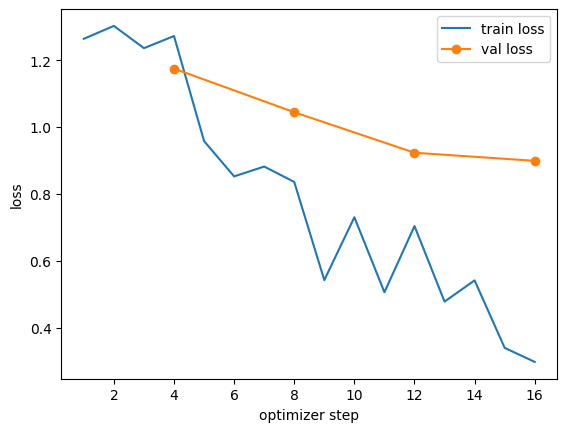

Adapter saved to ./lora_support_ticket_adapter -> ['adapter_model.safetensors', 'adapter_config.json', 'README.md']


In [8]:
# %% PART 4: LoRA configuration and training
lora_cfg = LoraConfig(
    r=16, lora_alpha=32, lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
model = get_peft_model(model, lora_cfg)   # base weights frozen; original NOT merged/overwritten
trainable, total = model.get_nb_trainable_parameters()
print(f"Total params={total:,} | trainable={trainable:,} | trained={100 * trainable / total:.3f}%")

args_kw = dict(
    output_dir="./lora_runs", num_train_epochs=4, per_device_train_batch_size=4,
    per_device_eval_batch_size=4, gradient_accumulation_steps=4,   # effective batch = 16
    learning_rate=2e-4, lr_scheduler_type="cosine", warmup_steps=10, weight_decay=0.0,
    logging_steps=1, save_strategy="no", report_to="none", seed=SEED,
    bf16=USE_BF16, fp16=USE_FP16, remove_unused_columns=False)
eval_key = "eval_strategy" if "eval_strategy" in inspect.signature(TrainingArguments.__init__).parameters \
    else "evaluation_strategy"
args_kw[eval_key] = "epoch"
training_args = TrainingArguments(**args_kw)

trainer = Trainer(model=model, args=training_args, train_dataset=train_ds,
                  eval_dataset=val_ds, data_collator=collator)
t0 = time.time()
train_result = trainer.train()
print(f"Training time: {(time.time() - t0) / 60:.1f} min")

hist = pd.DataFrame(trainer.state.log_history)
print("\nTraining loss (last logged steps):\n", hist[["step", "loss"]].dropna().tail(5))
print("\nValidation loss per epoch:\n", hist[["epoch", "eval_loss"]].dropna())
try:
    import matplotlib.pyplot as plt
    tr, ev = hist.dropna(subset=["loss"]), hist.dropna(subset=["eval_loss"])
    plt.plot(tr["step"], tr["loss"], label="train loss")
    plt.plot(ev["step"], ev["eval_loss"], "o-", label="val loss")
    plt.xlabel("optimizer step"); plt.ylabel("loss"); plt.legend(); plt.show()
except Exception as e:
    print("Plot skipped:", e)

model.save_pretrained(ADAPTER_DIR)       # saves ONLY the LoRA adapter (a few MB)
print("Adapter saved to", ADAPTER_DIR, "->", os.listdir(ADAPTER_DIR))


# Part 5: Post-Training Evaluation

Evaluate the fine-tuned model using the same prompt structure, generation settings, test inputs, and criteria used for the baseline model. Depending on the fine-tuning method that you used, this may involve "attaching" or "activating" the trained adapter into the base model.

**TODO:**

* Run the ``test_queries`` through your fine-tuned model and display the output in a comparison table with the baseline output.
* Compute the same metrics that you used in the baseline model evaluation and display the performance in a comparison table with the baseline metrics.

**Q12:** What changed most clearly after fine-tuning: task accuracy, formatting, terminology, consistency, or something else?

**A12:**Formatting and category choice changed most clearly. Format went from 0% to 80%, and category from 0% to 70%. Nearly every output now follows the exact three-line Category: / Priority: / Summary: layout with a label from the allowed set, and the summaries are consistently short sentences, usually starting with “User”. Summary pass rate rose from 30% to 100%, but that check is a heuristic, so I’d treat it as “more consistent and concise”, not necessarily more accurate. Priority did not meaningfully improve. The fine-tuned model output Priority: Low for all 10 requests. The 40% priority score comes only from the four queries where Low was an acceptable answer (rows 1, 5, 7, 8), so the model learned the format of the field but not how to judge urgency.

**Q13:** Identify one test item for which fine-tuning helped and explain the evidence.

**A13:**Row 1 (We were charged for six users, but only five people are on our account.) is a clear improvement. The baseline output was Authentication - Low\nPriority - Medium\nSummary: We were charged for six users, but only five people are on our account.: wrong category, broken format, and a summary that just copies the request. The fine-tuned output is Category: Billing\nPriority: Low\nSummary: User charges for 6 users when only 5 are registered. It has a correct category, an acceptable priority, valid format, and a summary in the dataset’s “User ...” style. This failed all four checks before (summary only via the heuristic) and passes all four now. Row 3 is a similar case (Feature Request becomes Data Export), though its summary adds an unsupported “as a PDF”.

**Q14:** Identify one test item for which fine-tuning did not help or made the response worse. What might explain that result?

**A14:**Row 7 got worse in category. The baseline’s Feature Request: Dark Mode Enhancement for App Performance identified the main request, even though the format was wrong. The fine-tuned model produced Category: Performance, with a summary about dark mode, so the category contradicts its own summary. A likely explanation is that the training set contains no mixed-intent examples, so the model matches on the keyword “slow” and picks Performance. It may also be over-reading the first clause of the request. Row 8 also failed. The model invented Category: Pricing, which isn’t in the allowed list and was never in the training data. It does not yet treat Other as a catch-all. I haven’t tested this, but a plausible reason is that the 56 training examples contain few pricing or sales-inquiry cases, so the base model’s own label prior leaked through.

The priority collapse is worth checking too. A quick test is to run generate_ticket on a few High-priority training examples. If it still outputs Low, the adapter is under-trained or the Low-heavy dataset (43% Low) is dominating. That would support adding more High and Medium examples.

In [9]:
# Code for PART 5

# %% PART 5: Post-training evaluation (same prompt, same greedy decoding, same test set, same metrics)
model.eval()
ft_df = run_eval(test_queries, mdl=model, label="fine-tuned")
ft_rates = success_rates(ft_df)

comparison_outputs = pd.DataFrame({
    "request": test_queries,
    "baseline_output": baseline_df["output"],
    "finetuned_output": ft_df["output"],
    "base_cat_ok": baseline_df["category_ok"], "ft_cat_ok": ft_df["category_ok"],
    "base_pri_ok": baseline_df["priority_ok"], "ft_pri_ok": ft_df["priority_ok"],
    "base_fmt_ok": baseline_df["format_ok"], "ft_fmt_ok": ft_df["format_ok"]})
print(comparison_outputs.to_string())

comparison_metrics = pd.DataFrame({"baseline_%": baseline_rates, "finetuned_%": ft_rates})
comparison_metrics["change_pts"] = comparison_metrics["finetuned_%"] - comparison_metrics["baseline_%"]
print("\n", comparison_metrics.round(1))

                                                                                request                                                                                                  baseline_output                                                                                                   finetuned_output  base_cat_ok  ft_cat_ok  base_pri_ok  ft_pri_ok  base_fmt_ok  ft_fmt_ok
0  I changed phones and now the verification code is still being sent to my old number.  Category: Authentication\nPriority: Low\nSummary: Verification code is still being sent to an old phone number.    Category: Authentication\nPriority: Low\nSummary: Verification code is still being sent to an old phone number.         True       True        False      False         True       True
1               We were charged for six users, but only five people are on our account.                  Category: Billing\nPriority: Low\nSummary: User charges for 6 users when only 5 are registered.                    Cate

# Part 6: Generalization and Failure Testing

A fine-tuned model may perform well on examples similar to its training data but fail when the input is ambiguous, out of distribution, or missing important information.

**TODO:**

Create at least three new test requests:

1. One request that closely matches the training domain but uses unfamiliar wording.
2. One ambiguous request that could reasonably receive more than one category or priority.
3. One out-of-domain request that does not belong in the support-ticket categories.

Run both the baseline and fine-tuned models on these requests.

**Q15:** Reflect on how the model responded to each of these new examples. Was the fine-tuned model more or less adaptable than the baseline model? How did the model categorize the out-of-domain example? Does this behavior suggest any changes to your fine-tuning methods or dataset?

**A15:**used three new requests:

Familiar domain, unfamiliar wording: “My credentials keep getting bounced whenever I try to enter the portal from my tablet.”
Ambiguous: “I can’t access my account since the payment failed.”
Out of domain: “What’s a good recipe for vegetarian lasagna?”

Request 1 (unfamiliar wording). The fine-tuned model handled this well: Category: Authentication, valid three-line format, and a sensible summary (User's credentials are being bounced when logging in from a tablet.). It generalized beyond the training phrasing, since “credentials bounced” and “enter the portal” don’t appear in the training set. The baseline also understood the issue (Authentication - Medium\nSummary: Credentials bouncing on tablet...) but broke the template, with no Category: or Priority: labels. The fine-tuned model’s Priority: Low is questionable for a user who can’t get in, which is the same priority weakness as in Part 5.

Request 2 (ambiguous). This could reasonably be Billing, Account Management or Authentication, and the priority could be Medium or High. The fine-tuned model chose Authentication with Priority: Low and wrote User cannot log in due to a failed payment. It is a defensible category but not the only one, and the summary adds an assumption (“log in”) that the request never states. The model commits confidently to one reading, with no sign of uncertainty. The baseline chose Authentication too, in a scrambled format (Authentication - Low\nSummary: ...\n\nPriority: Medium\nCategory: Authentication), so neither model resolved the ambiguity better than the other. The difference is that the fine-tuned output is machine-readable.

Request 3 (out of domain). The fine-tuned model output Category: Recipe, which is not one of the seven allowed categories (it failed the format check), and its summary was User asks about a vegetarian lasagna recipe. It followed the template and the style but didn’t respect the closed label set, when Other was the right answer. The baseline was also wrong: Feature Request: Need information on vegetarian lasagna recipes. It forced the request into a support category and broke the format. So fine-tuning changed the type of failure, from a wrong category in the wrong format to an invented category in the right format.

Adaptability. The fine-tuned model was more consistent than the baseline: it produced the required structure on all three new inputs, where the baseline produced it on none. I would not call it more adaptable in the sense that matters here. In total across Parts 5 and 6, it invented labels outside the allowed list three times (User Management, Pricing, Recipe), so it learned the surface format better than the rule that categories come from a closed list. Priority also remained Low on all three new requests, which matches the collapse in the test set. These are single greedy outputs on three examples, so treat them as illustrations, not statistics.

Changes to the dataset and method. This behavior points to several fixes:

Add genuine off-topic examples labeled Other. My current Other examples (support hours, partner program, resume, privacy policy) are all company-related, so the model never saw a clearly unrelated request mapped to Other. A handful (recipes, weather, general trivia) would teach that Other is the catch-all.
Add more pricing, sales and plan-inquiry examples, since the model invented Pricing for the nonprofit query.
Add more Other examples overall (only 8 of 67) and more High and Medium examples for the low-urgency categories, so priority depends on urgency cues, not on category.
Include a few deliberately ambiguous and mixed-intent examples with a consistent labeling convention (for example, label by the user’s main request), to reduce guessing on cases like “slow but I want dark mode” and the payment-failure request.
Train longer or with more data (more epochs, or a larger set of varied examples), and track whether validation loss keeps falling.
Constrain the output. Add a post-generation check that rejects any category outside the list and falls back to Other or regenerates, or use constrained decoding. This is a more reliable fix than hoping the adapter learns a closed set from 56 examples.

In [10]:
# Code for PART 6

# %% PART 6: Generalization and failure testing
new_tests = [
    # 1. In-domain, unfamiliar wording (Authentication)
    "My credentials keep getting bounced whenever I try to enter the portal from my tablet.",
    # 2. Ambiguous (Billing? Account Management? Authentication?)
    "I can't access my account since the payment failed.",
    # 3. Out-of-domain (should ideally be 'Other')
    "What's a good recipe for vegetarian lasagna?",
]
GOLD.update({  # reference labels so the evaluator can score them (ambiguous one accepts several)
    new_tests[0]: dict(cats={"Authentication"}, pris={"Medium", "High"}, kw={"login", "log", "credential", "access", "tablet", "portal"}),
    new_tests[1]: dict(cats={"Billing", "Account Management", "Authentication"}, pris={"Medium", "High"}, kw={"payment", "access", "account", "failed"}),
    new_tests[2]: dict(cats={"Other"}, pris={"Low"}, kw={"recipe", "lasagna", "vegetarian", "unrelated", "request"}),
})

with model.disable_adapter():                      # base-model behavior, adapter temporarily off
    base_new = run_eval(new_tests, mdl=model, label="baseline-new")
ft_new = run_eval(new_tests, mdl=model, label="finetuned-new")   # adapter active

gen_table = pd.DataFrame({"request": new_tests,
                          "baseline_output": base_new["output"],
                          "finetuned_output": ft_new["output"],
                          "base_fmt_ok": base_new["format_ok"], "ft_fmt_ok": ft_new["format_ok"],
                          "base_category": base_new["pred_category"],
                          "ft_category": ft_new["pred_category"]})
print(gen_table.to_string())

# Sanity check: adapter-disabled outputs on test_queries should match the stored baseline
with model.disable_adapter():
    chk = generate_ticket(test_queries[0], model)
print("\nAdapter-off reproduces baseline output:", chk == baseline_df["output"].iloc[0])

                                                                                  request                                                                                                       baseline_output                                                                                                                         finetuned_output  base_fmt_ok  ft_fmt_ok   base_category     ft_category
0  My credentials keep getting bounced whenever I try to enter the portal from my tablet.                         Authentication - Medium\nSummary: Credentials bouncing on tablet during portal login attempt.  Category: Authentication\nPriority: Low\nSummary: Portal authentication is frequently being bounced when trying to log in via a tablet.        False       True            None  Authentication
1                                     I can't access my account since the payment failed.  Authentication - Low\nSummary: Payment failure issue in account access\n\nPriority: Medium\nCategory: Authe

# Part 7: AI Assistance Reflection

You are expected to use an AI assistant to help with code generation, debugging, dataset formatting, or interpretation. You remain responsible for understanding the workflow and validating the assistant’s suggestions.

**Q16:** Which AI assistant or assistants did you use, and what parts of the work did they help with?

**A16:**I used Claude (Anthropic’s AI assistant) throughout the project. It helped with:

Choosing a model small enough for the compute constraint (Qwen2.5-0.5B-Instruct).
Writing the full Python workflow: the prompt and generation function, the rule-based evaluator, the baseline run, the synthetic dataset with leakage checks, tokenization with label masking, the LoRA configuration and training, and the Part 5 and 6 comparison tables.
Debugging environment errors.
Helping me interpret my outputs and draft the written answers, which I reviewed against my own results.

**Q17:** Describe one AI-generated suggestion that helped you resolve a technical or data-formatting problem.

**A17:**The most useful fix was for the ImportError from datasets, which failed on a broken pyarrow DLL (The pyarrow installation is not built with support for 'dataset'). Claude suggested removing the dependency instead of repairing the environment, replacing Dataset.from_list with a small ListDataset class that the Hugging Face Trainer can use directly. That fixed the problem without any package changes. The other helpful suggestion was masking prompt tokens with -100 and padding labels with -100 in the collator, so loss was computed only on the three-line response. I confirmed this by decoding the trainable label tokens of the first example, which showed only the response.

**Q18:** Describe one suggestion that was incorrect, incompatible with your model or environment, or inappropriate for the assignment.

**A18:**Several suggestions or outputs were wrong or didn’t fit my environment:

Environment incompatibility: the first get_peft_model call failed with ImportError: Found an incompatible version of torchao, because the Colab runtime’s preinstalled torchao was too old for the installed peft. I had to uninstall torchao and restart the runtime, which wiped the in-memory baseline results.
Dataset-size error: the assistant first said the dataset had 68 examples, but the code produced 67, so I used the printed count.
Misinterpreted baseline: my Part 2 baseline cell was rerun after training, with the adapter active, so it showed fine-tuned results (70% category, 80% format) instead of the true baseline (0% category, 0% format). The assistant’s first draft answers for Q4 and Q5 were written from that contaminated table and had to be rewritten. The fix was to compute the baseline with model.disable_adapter(), and the check Adapter-off reproduces baseline output: True confirmed it.
Weak evaluation heuristic: the summary check passed inaccurate summaries (for example, the baseline’s copy of the request in row 1 and the fine-tuned row 9 summary that invented a refund request), so the 100% summary rate overstates quality and needed manual reading.

**Q19:** What parts of the training and evaluation workflow did you need to verify or decide independently?

**A19:**I had to verify or decide the following myself:

Reference labels: the acceptable categories and priorities for each test query (for example, whether the nonprofit pricing request could be Other or Billing), and the keyword lists behind the summary check, are my own judgment calls.
Whether results were real: I checked that the baseline was measured with the adapter off and that the training data contained no test queries (the leakage assertion). I also noticed the baseline mix-up above.
Reading outputs, not just metrics: the summary pass rate hid factual errors, and the 40% priority score came from the model outputting Low for every request.
Compute and training settings: the model size, LoRA rank, learning rate, epochs and batch size, and the decision to run on CPU in fp32. I checked that the training and validation loss both fell, while remembering that an 11-example validation set is noisy.
Dataset quality: whether labels were consistent and balanced (priority skewed toward Low) and whether examples needed revising.
Generalization: judging the Part 6 outputs, including the invented Recipe category, and deciding what dataset changes they suggest.